# 2.16 · Metropolis: the random walk

**Before this:** [2.02](2-02_bayes_in_pictures.ipynb) (posterior shapes), [2.03](2-03_probability_distributions.ipynb) (distributions); [2.15](2-15_map_of_methods.ipynb) gives the overview.
**You will be able to:** run and tune a random-walk Metropolis sampler; explain why the acceptance rule targets the
posterior (detailed balance) and when the Hastings correction is needed; read a trace, an autocorrelation curve and
an effective sample size; say why correlation, curvature and dimension slow a random walk.
**Optional sections:** 7 (banana).

Metropolis (Metropolis et al. 1953) is the simplest sampler and the ancestor of all the others. It needs only
one thing from your model: the value of the log posterior at a point. No gradient, no derivative of the forward
model, no Gaussian assumption. That makes it robust and universal. It also makes it slow, and this notebook shows
exactly why: it walks blindly, one small random step at a time.

**Words this notebook defines:** proposal, acceptance and rejection, step size, acceptance rate, random walk,
autocorrelation, effective sample size (ESS).

**Problems in this notebook** (size and forward model; notebook 2.25 explains the degree of nonlinearity)

| problem | unknowns | data | forward model | linear? |
|---|---|---|---|---|
| trade-off (most sections) | 2 | 2 | $\mathbf d = \mathbf G\mathbf m$ | linear |
| round Gaussian (step size) | 2 | 2 | $\mathbf d = \mathbf G\mathbf m$ | linear |
| correlated Gaussians, ρ from 0 to 0.999 (5) | 2 | none | target density only | no data |
| standard Gaussian in d dimensions (6) | 1 to 100 | none | target density only | no data |
| banana (7) | 2 | 1 | distance to one station | nonlinear |

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import inspect
import numpy as np
import matplotlib.pyplot as plt
import jax.numpy as jnp
import bayeskit as bk
from bayeskit import problems as P, samplers as SM, diagnostics as D, plotting as BP, style as S

ORANGE = S.COLORS["rwm"]

## 1. The algorithm in words

1. Stand at a point $\mathbf m$.
2. **Propose** a nearby point $\mathbf m' = \mathbf m + s\,\mathbf z$, with $\mathbf z$ a standard normal vector and $s$
   the **step size**.
3. Compare heights. If $p(\mathbf m') \ge p(\mathbf m)$, move there. If it is lower, move there with probability
   $p(\mathbf m')/p(\mathbf m)$. That is the **acceptance** test.
4. If the proposal is **rejected**, stay, and *record the current point again*.
5. Repeat thousands of times. The recorded points are the samples.

The sequence of recorded points is a **chain**, and because each step depends only on where the walker is now (not
on how it got there) it is a **Markov chain** (2.15). Methods that sample this way are called MCMC, Markov chain
Monte Carlo.

Two details carry the whole idea.
* **Only the ratio** $p(\mathbf m')/p(\mathbf m)$ is needed. The normalising constant of the posterior (the
  **evidence** $p(\mathbf d)$, the integral of prior × likelihood over all parameters, 2.04; it is rarely computable
  in more than a few dimensions) cancels. This is why MCMC works on an unnormalised posterior.
* **A rejection repeats the current point.** The chain must spend time at each place in proportion to its
  probability. A rejection means "the place you wanted to go is less probable than here", so the chain lingers
  here a little longer. Dropping the repeats would throw that information away and over-represent the
  improbable regions.

The whole implementation used in this series is short. The line that does the work is the one marked
"the whole algorithm is this line":

In [2]:
print(inspect.getsource(SM.rwm))

def rwm(target, x0, n, step, cov=None, rng=None, record=False):
    """Random-walk Metropolis for one or several chains at once.

    x0: (d,) or (C, d) start points.  step: proposal scale.  cov: proposal shape (default identity).
    One iteration:  propose y = x + step * L z,  accept with probability min(1, p(y)/p(x)),  otherwise stay.
    Returns samples (C, n, d), accepted flags (C, n), and (if record) the proposals.
    """
    rng = rng or np.random.default_rng()
    X = np.atleast_2d(np.asarray(x0, float)).copy()
    C, d = X.shape
    Lc = np.linalg.cholesky(np.asarray(cov, float)) if cov is not None else np.eye(d)
    lp = target.logp_batch(X)
    S = np.empty((C, n, d))
    A = np.zeros((C, n), bool)
    LP = np.empty((C, n))
    Pr = np.empty((C, n, d)) if record else None
    for i in range(n):
        Y = X + step * rng.standard_normal((C, d)) @ Lc.T
        lpy = target.logp_batch(Y)
        acc = np.log(rng.uniform(size=C)) < lpy - lp          # the whole algorithm is th

### Why this rule samples the posterior: detailed balance

**In plain words.** Imagine many walkers spread over the parameter space exactly in proportion to the posterior.
After every walker takes one Metropolis step, the crowd should look the same. The acceptance rule guarantees this by
making the flow between any two points equal in both directions: as many walkers go from $\mathbf m$ to $\mathbf m'$
as from $\mathbf m'$ to $\mathbf m$. A crowd that is already right then stays right, and a chain that wanders long
enough ends up spending its time in proportion to the posterior.

**Precisely.** Write $\pi$ for the (unnormalised) posterior, $q(\mathbf m'\mid\mathbf m)$ for the proposal density and
$\alpha$ for the acceptance probability. **Detailed balance** is
$$\pi(\mathbf m)\,q(\mathbf m'\mid\mathbf m)\,\alpha(\mathbf m\to\mathbf m') = \pi(\mathbf m')\,q(\mathbf m\mid\mathbf m')\,\alpha(\mathbf m'\to\mathbf m),$$
and the **Metropolis-Hastings** choice that satisfies it is
$$\alpha(\mathbf m\to\mathbf m') = \min\!\Big(1,\ \frac{\pi(\mathbf m')\,q(\mathbf m\mid\mathbf m')}{\pi(\mathbf m)\,q(\mathbf m'\mid\mathbf m)}\Big).$$
For a **symmetric** proposal, such as $\mathbf m' = \mathbf m + s\,\mathbf z$ above, $q(\mathbf m'\mid\mathbf m) =
q(\mathbf m\mid\mathbf m')$, the $q$ terms cancel and the rule is the ratio $\pi(\mathbf m')/\pi(\mathbf m)$ used in
this notebook (Metropolis et al. 1953). For an **asymmetric** proposal the $q$ ratio, the **Hastings correction**
(Hastings 1970), must stay. Detailed balance makes $\pi$ a **stationary distribution** of the chain: a distribution
that one more step leaves unchanged (walkers spread according to $\pi$ are still spread according to $\pi$ after the
step). Two more conditions make the long-run histogram of one chain converge to $\pi$: **irreducibility** (from any
point the chain can eventually reach every region of positive probability) and **aperiodicity** (it does not cycle
with a fixed period). None of this says how fast; the rest of this notebook is about speed.

**Worked example: forgetting the correction.** A positive parameter $x$ (a viscosity, a rate) is often proposed
multiplicatively, $x' = x\,e^{s z}$, a symmetric step in $\ln x$. In $x$ this proposal is asymmetric:
$q(x\mid x')/q(x'\mid x) = x'/x$. Take the target $\pi(x) \propto x\,e^{-x}$ (a Gamma(2, 1) distribution, mean 2) and
run the chain with and without that factor.

with the Hastings correction: sample mean 1.994, sample variance 1.975  (target Gamma(2, 1): mean 2, variance 2; Exponential(1): mean 1, variance 1)
without the Hastings correction: sample mean 0.999, sample variance 1.014  (target Gamma(2, 1): mean 2, variance 2; Exponential(1): mean 1, variance 1)
saved figures/2-16_hastings.png


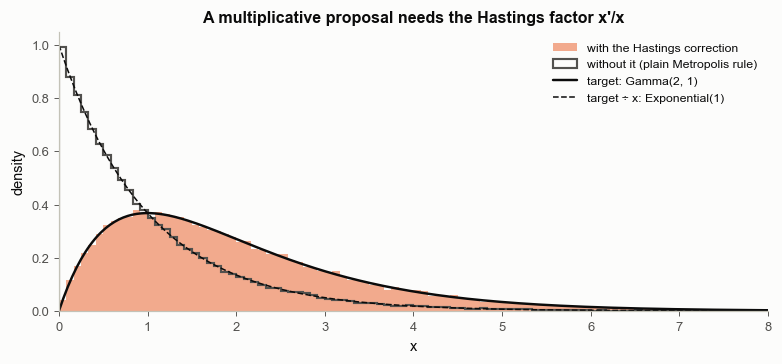

In [3]:
def multiplicative_mh(logpi, x0, n, s, rng, hastings=True):
    """Metropolis-Hastings for a positive parameter with the multiplicative proposal x' = x exp(s z)."""
    x = np.array(x0, float)
    out = np.empty((n, x.size))
    for i in range(n):
        xp = x * np.exp(s * rng.standard_normal(x.size))
        log_a = logpi(xp) - logpi(x) + (np.log(xp) - np.log(x) if hastings else 0.0)   # log q(x|x') - log q(x'|x) = log(x'/x)
        acc = np.log(rng.uniform(size=x.size)) < log_a
        x = np.where(acc, xp, x)
        out[i] = x
    return out


logpi_gamma = lambda x: np.log(x) - x                    # Gamma(2, 1), unnormalised
rng_h = np.random.default_rng(16)
runs_h = {h: multiplicative_mh(logpi_gamma, np.ones(8), 20000, 0.8, rng_h, hastings=h)[2000:].ravel() for h in (True, False)}
for h, xs in runs_h.items():
    print(f"{'with' if h else 'without'} the Hastings correction: sample mean {xs.mean():.3f}, sample variance {xs.var():.3f}"
          f"  (target Gamma(2, 1): mean 2, variance 2; Exponential(1): mean 1, variance 1)")

fig, ax = plt.subplots(figsize=(7.2, 3.4))
xg = np.linspace(0, 10, 400)
ax.hist(runs_h[True], bins=120, range=(0, 10), density=True, color=ORANGE, alpha=0.55, label="with the Hastings correction")
ax.hist(runs_h[False], bins=120, range=(0, 10), density=True, histtype="step", color=S.INK2, lw=1.4,
        label="without it (plain Metropolis rule)")
ax.plot(xg, xg * np.exp(-xg), color=S.INK, lw=1.6, label="target: Gamma(2, 1)")
ax.plot(xg, np.exp(-xg), color=S.INK, lw=1.0, ls="--", label="target ÷ x: Exponential(1)")
ax.set_xlabel("x"); ax.set_ylabel("density"); ax.set_xlim(0, 8)
ax.set_title("A multiplicative proposal needs the Hastings factor x'/x")
ax.legend(fontsize=8)
fig.tight_layout()
bk.savefig(fig, "2-16_hastings")
plt.show()

**How to read it.** With the correction the histogram follows the target. Without it the chain is still a perfectly
good Markov chain, but of the wrong distribution: it samples $\pi(x)/x$, which here is the Exponential(1) (printed
means near 1 instead of 2). Nothing in the trace would warn you. Whenever a proposal is not a symmetric step in the
coordinates in which you write the density, include the Hastings factor, or equivalently sample in the coordinates
where the step is symmetric ($\ln x$ here) and add the Jacobian of the change of variables to the target (2.11).

## 2. Watching it: proposals, accepts and rejects

The trade-off problem from notebook 2.02 (two slip patches that a distant station sees almost equally), with an
isotropic proposal. Orange: the chain and the accepted moves. Red ×: a rejected proposal (the chain stays put
and records the same point again).

rho of this posterior = -0.983; accepted 25 of 110 proposals (rate 0.23)


saved figures/2-16_rwm_animation_final.png


saved figures/2-16_rwm_animation.gif (1.8 MB)



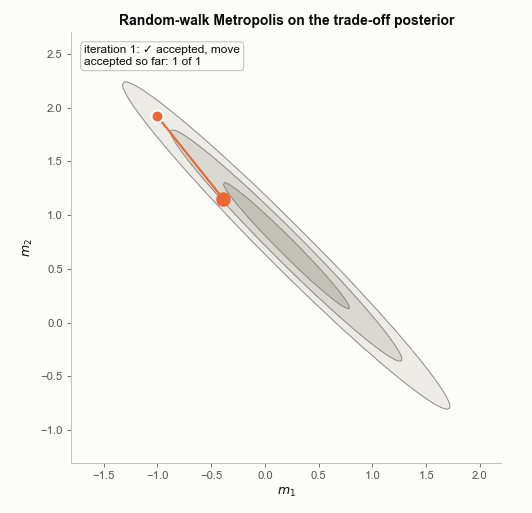

The last frame at full resolution (300 dpi):


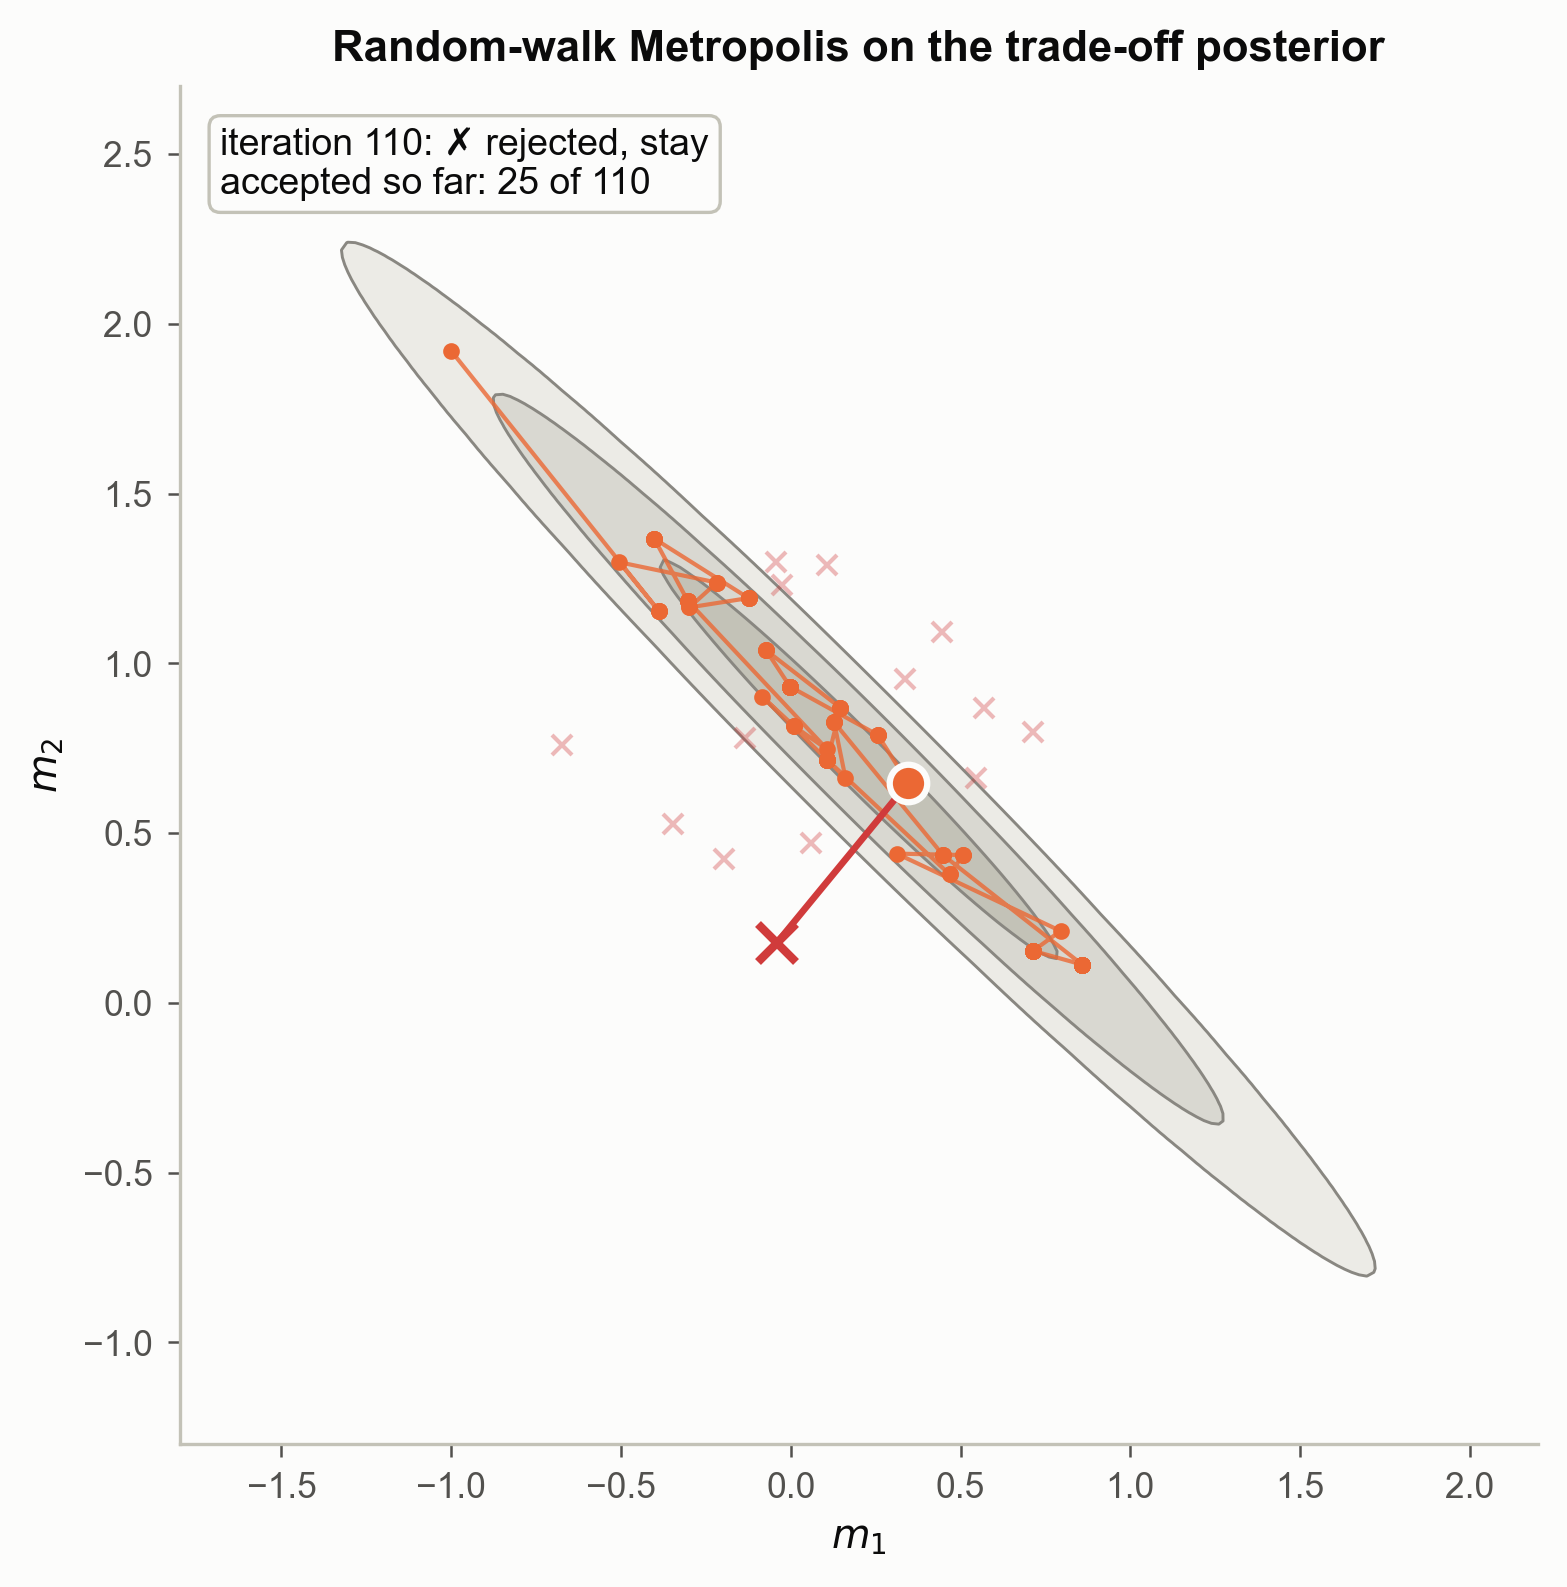

In [4]:
pr = P.correlated()
gC = P.grid(pr, n=300)
ext = (-1.8, 2.2, -1.3, 2.7)
rng = np.random.default_rng(3)
start = np.array([-1.0, 1.92])
K = 110
anim = SM.rwm(pr, start, K, step=0.3, rng=rng, record=True)
ch, prop, acc = anim["chain"], anim["proposals"][0], anim["accepted"][0]
before = np.vstack([start, ch[:-1]])              # position before each proposal
print("rho of this posterior = %.3f; accepted %d of %d proposals (rate %.2f)"
      % (pr.exact[1][0, 1] / np.sqrt(pr.exact[1][0, 0] * pr.exact[1][1, 1]), acc.sum(), K, acc.mean()))


def base_axes(ax):
    BP.density(ax, gC)
    ax.set_xlim(ext[0], ext[1]); ax.set_ylim(ext[2], ext[3]); ax.set_aspect("equal")
    ax.set_xlabel(pr.labels[0]); ax.set_ylabel(pr.labels[1])


fig, ax = plt.subplots(figsize=(5.6, 5.4), dpi=95)
base_axes(ax)
trail, = ax.plot([], [], "-", color=ORANGE, lw=1.0, alpha=0.8, zorder=4)
trail_pts, = ax.plot([], [], "o", color=ORANGE, ms=3, zorder=4)
old_rej, = ax.plot([], [], "x", color=S.BAD, ms=5, mew=1.0, alpha=0.35, zorder=4)
seg, = ax.plot([], [], "-", lw=1.6, zorder=6)
tip, = ax.plot([], [], "o", ms=9, zorder=7)
cur, = ax.plot([], [], "o", color=ORANGE, ms=9, mec=S.SURFACE, mew=1.5, zorder=8)
txt = ax.text(0.03, 0.97, "", transform=ax.transAxes, va="top", ha="left", fontsize=9,
              bbox=dict(boxstyle="round,pad=0.3", fc=S.SURFACE, ec=S.AXIS, lw=0.8))
ax.set_title("Random-walk Metropolis on the trade-off posterior")
fig.tight_layout()
frames = []
for i in range(K):
    path = np.vstack([start, ch[:i]])
    trail.set_data(path[:, 0], path[:, 1]); trail_pts.set_data(path[:, 0], path[:, 1])
    rej_idx = [k for k in range(max(0, i - 15), i) if not acc[k]]
    old_rej.set_data(prop[rej_idx, 0], prop[rej_idx, 1])
    x0, x1 = before[i], prop[i]
    col = ORANGE if acc[i] else S.BAD
    seg.set_data([x0[0], x1[0]], [x0[1], x1[1]]); seg.set_color(col)
    tip.set_data([x1[0]], [x1[1]]); tip.set_color(col); tip.set_marker("o" if acc[i] else "x")
    tip.set_markeredgewidth(2.0)
    cur.set_data([x0[0]], [x0[1]])
    txt.set_text(f"iteration {i + 1}: {'✓ accepted, move' if acc[i] else '✗ rejected, stay'}\n"
                 f"accepted so far: {acc[:i + 1].sum()} of {i + 1}")
    frames.append(S.fig_to_rgb(fig))
final_png = bk.savefig(fig, "2-16_rwm_animation_final")       # the last frame as a 300-dpi still
plt.close(fig)
gif = S.frames_to_gif(frames, S.FIG / "2-16_rwm_animation.gif", fps=6, hold_last=10)
print("saved figures/2-16_rwm_animation.gif (%.1f MB)" % (gif.stat().st_size / 1e6))
S.show_gif(gif)
from IPython.display import Image as _Image, display as _display
print("The last frame at full resolution (300 dpi):")
_display(_Image(filename=str(final_png), width=520))

The same 50 first iterations as one still picture (for print):

saved figures/2-16_rwm_first50.png


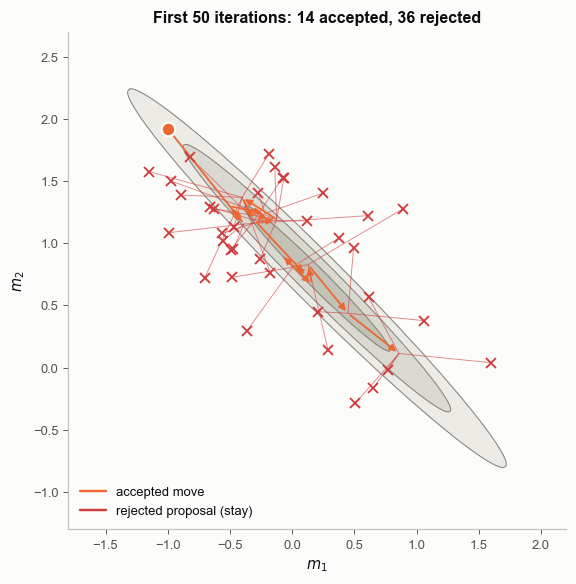

In [5]:
fig, ax = plt.subplots(figsize=(5.6, 5.4))
base_axes(ax)
n50 = 50
for i in range(n50):
    x0, x1 = before[i], prop[i]
    if acc[i]:
        ax.annotate("", xy=x1, xytext=x0, arrowprops=dict(arrowstyle="-|>", color=ORANGE, lw=1.2, mutation_scale=9), zorder=5)
    else:
        ax.plot([x0[0], x1[0]], [x0[1], x1[1]], "-", color=S.BAD, lw=0.6, alpha=0.6, zorder=4)
        ax.plot(*x1, "x", color=S.BAD, ms=6, mew=1.2, zorder=5)
ax.plot(*start, "o", color=ORANGE, ms=9, mec=S.SURFACE, mew=1.5, zorder=6)
ax.legend(handles=BP.legend_handles([("accepted move", ORANGE, "line"), ("rejected proposal (stay)", S.BAD, "line")]),
          loc="lower left")
ax.set_title("First 50 iterations: %d accepted, %d rejected" % (acc[:n50].sum(), n50 - acc[:n50].sum()))
fig.tight_layout()
bk.savefig(fig, "2-16_rwm_first50")
plt.show()

**The image to keep.** The proposal does not know where the ridge is. Most proposals land off the narrow ridge
(low probability) and are rejected; the few that land along it are accepted. The chain creeps along the ridge
in short, randomly directed steps: a **random walk**.

## 3. Step size: too small, tuned, too large

The only knob is the step size $s$. To see its effect cleanly we use the round Gaussian posterior from notebook 2.02
(on the trade-off posterior even the best isotropic step mixes poorly; section 5 is about that). Each row is one
step size. Left: the first 500 steps over the exact posterior. Middle: the **trace** (value of $m_1$ at every
iteration). Right: the **autocorrelation**, the correlation between draws $k$ iterations apart.

      step   size  acceptance   ESS of m1 (4 x 5000 draws)  ESS per 1000 draws
 too small   0.02       0.969                            4                 0.2
     tuned   0.60       0.336                         2212               110.6
 too large   6.00       0.005                           66                 3.3


saved figures/2-16_step_size.png


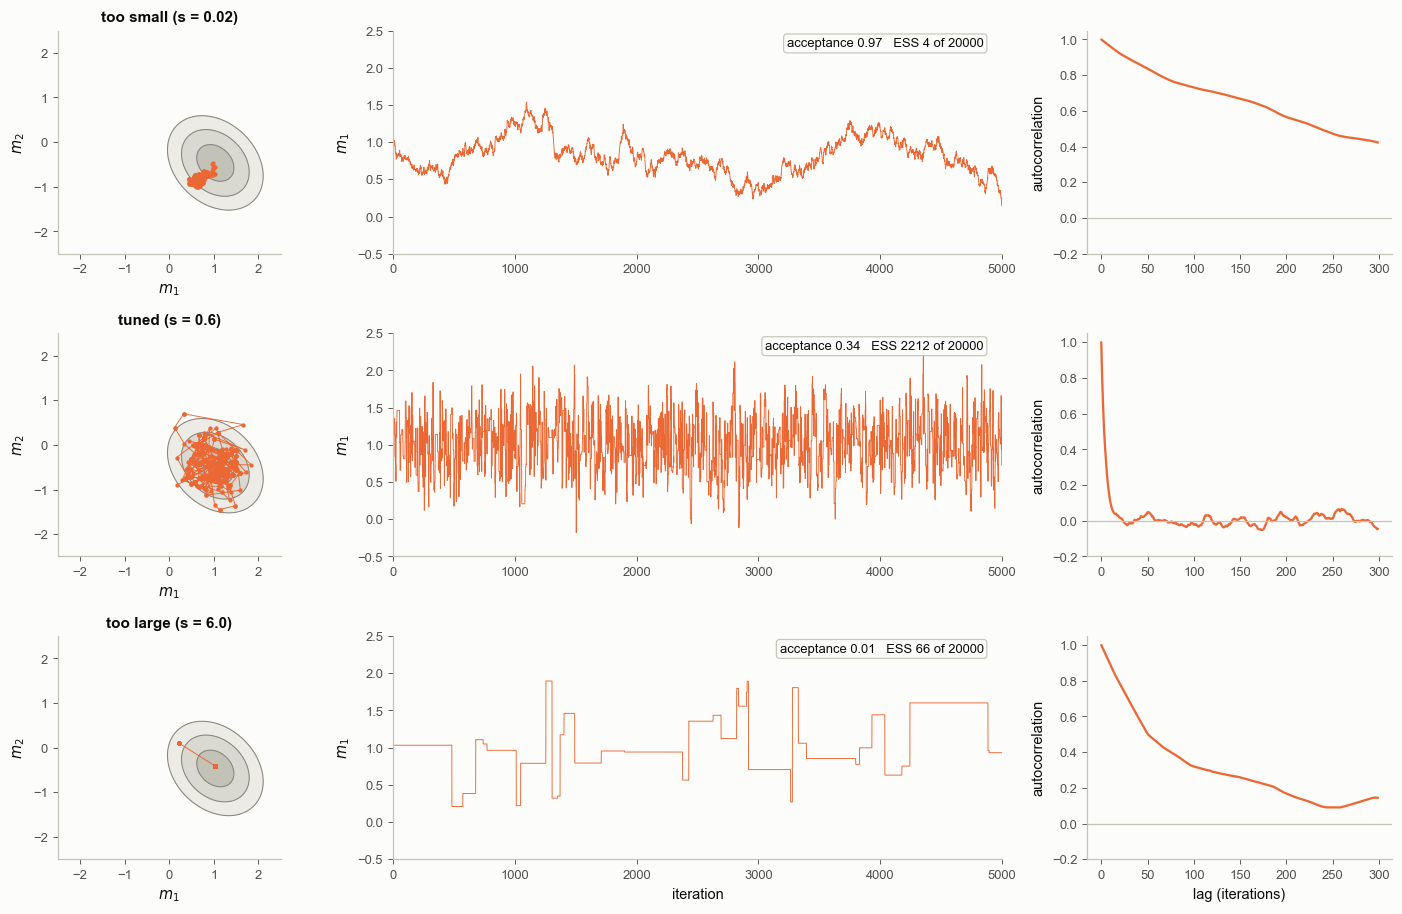

In [6]:
gp = P.gaussian()
gG = P.grid(gp, n=300)
m_ex, C_ex = gp.exact
steps = {"too small": 0.02, "tuned": 0.6, "too large": 6.0}
runs = {}
for k, (name, s) in enumerate(steps.items()):
    r = SM.rwm(gp, m_ex + 0.05 * np.random.default_rng(10 + k).standard_normal((4, 2)), 5000, step=s,
               rng=np.random.default_rng(20 + k))
    runs[name] = r
print(f"{'step':>10s} {'size':>6s} {'acceptance':>11s} {'ESS of m1 (4 x 5000 draws)':>28s} {'ESS per 1000 draws':>19s}")
for name, s in steps.items():
    r = runs[name]
    e = D.ess(r["samples"][:, :, 0])
    r["ess"] = e
    print(f"{name:>10s} {s:6.2f} {r['accept_rate']:11.3f} {e:28.0f} {e / 20:19.1f}")

fig, axs = plt.subplots(3, 3, figsize=(13, 8.4), gridspec_kw=dict(width_ratios=[1, 2.2, 1.1]))
for row, name in enumerate(steps):
    r = runs[name]
    c1 = r["samples"][0]
    ax = axs[row, 0]
    BP.density(ax, gG)
    ax.plot(c1[:500, 0], c1[:500, 1], "-o", color=ORANGE, lw=0.6, ms=1.8)
    BP.frame(ax, gp, equal=True)
    ax.set_title(f"{name} (s = {steps[name]})", fontsize=10)
    ax = axs[row, 1]
    BP.trace(ax, c1[:, 0], ORANGE, lw=0.6)
    ax.set_ylabel("$m_1$")
    ax.set_ylim(-0.5, 2.5)
    S.badge(ax, f"acceptance {r['accept_rate']:.2f}   ESS {r['ess']:.0f} of 20000", loc="upper right")
    ax = axs[row, 2]
    ac = D.autocorr(c1[:, 0], 300)
    ax.plot(np.arange(ac.size), ac, color=ORANGE)
    ax.axhline(0, color=S.AXIS, lw=0.8)
    ax.set_ylim(-0.2, 1.05)
    ax.set_ylabel("autocorrelation")
axs[2, 1].set_xlabel("iteration")
axs[2, 2].set_xlabel("lag (iterations)")
fig.tight_layout()
bk.savefig(fig, "2-16_step_size")
plt.show()

**How to read it.**
* **Too small:** almost every proposal is accepted, but each move is tiny. The path is a short squiggle, the
  trace drifts like a slow snake, and draws stay correlated for hundreds of iterations.
* **Too large:** proposals jump far into improbable territory and are almost all rejected. The chain sits still
  for long stretches: the flat steps in the trace. Again, draws stay correlated for a long time.
* **Tuned:** moves are as large as possible while still being accepted reasonably often. The trace looks like
  a fuzzy caterpillar and the autocorrelation falls to about zero within a few tens of lags.

The **effective sample size** (ESS, first met in 2.05) in the badges is the number of *independent* draws the chain is worth. Here is the
whole scan, as ESS against acceptance rate:

best step in the scan: s = 0.65, acceptance 0.31, ESS per 1000 draws 107
saved figures/2-16_step_scan.png


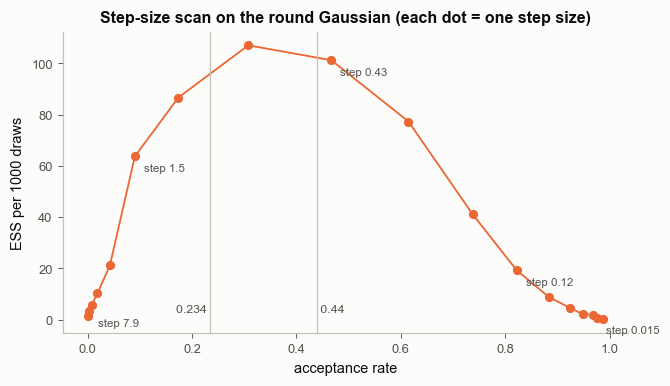

In [7]:
scan_steps = np.geomspace(0.01, 12, 18)
scan = []
for k, s in enumerate(scan_steps):
    r = SM.rwm(gp, m_ex + 0.05 * np.random.default_rng(100 + k).standard_normal((4, 2)), 5000, step=s,
               rng=np.random.default_rng(200 + k))
    scan.append((s, r["accept_rate"], D.ess(r["samples"][:, :, 0]) / 20))
scan = np.array(scan)
best = scan[np.argmax(scan[:, 2])]
print("best step in the scan: s = %.2f, acceptance %.2f, ESS per 1000 draws %.0f" % tuple(best))
fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.plot(scan[:, 1], scan[:, 2], "-o", color=ORANGE, ms=5, lw=1.2)
for s, a, e in scan[[1, 6, 9, 12, 16]]:
    ax.annotate(f"step {s:.2g}", (a, e), textcoords="offset points", xytext=(6, -10), fontsize=7.5, color=S.INK2)
ax.axvline(0.234, color=S.AXIS, lw=0.8); ax.axvline(0.44, color=S.AXIS, lw=0.8)
ax.text(0.234, 2, "0.234 ", fontsize=8, color=S.INK2, ha="right", va="bottom")
ax.text(0.44, 2, " 0.44", fontsize=8, color=S.INK2, ha="left", va="bottom")
ax.set_xlabel("acceptance rate")
ax.set_ylabel("ESS per 1000 draws")
ax.set_title("Step-size scan on the round Gaussian (each dot = one step size)")
fig.tight_layout()
bk.savefig(fig, "2-16_step_scan")
plt.show()

Efficiency peaks at an intermediate acceptance rate and collapses at both ends. The textbook guides are
acceptance ≈ 0.44 in one dimension and ≈ 0.234 for many independent dimensions (Roberts, Gelman & Gilks 1997;
Roberts & Rosenthal 2001). They are guides for picking a step, not goals in themselves: **the goal is ESS**, and
acceptance rate is only a cheap symptom of whether the step size is in the right range.

## 4. What "effective sample size" means, in one picture

Take a sticky chain (step 0.05 on the same round Gaussian, 4 chains × 5,000 draws) and compare its histogram of
$m_1$ with 20,000 truly independent draws from the exact posterior, and with only ESS-many independent draws.

sticky chain: acceptance 0.93, ESS 64 of 20000 draws
saved figures/2-16_ess_meaning.png


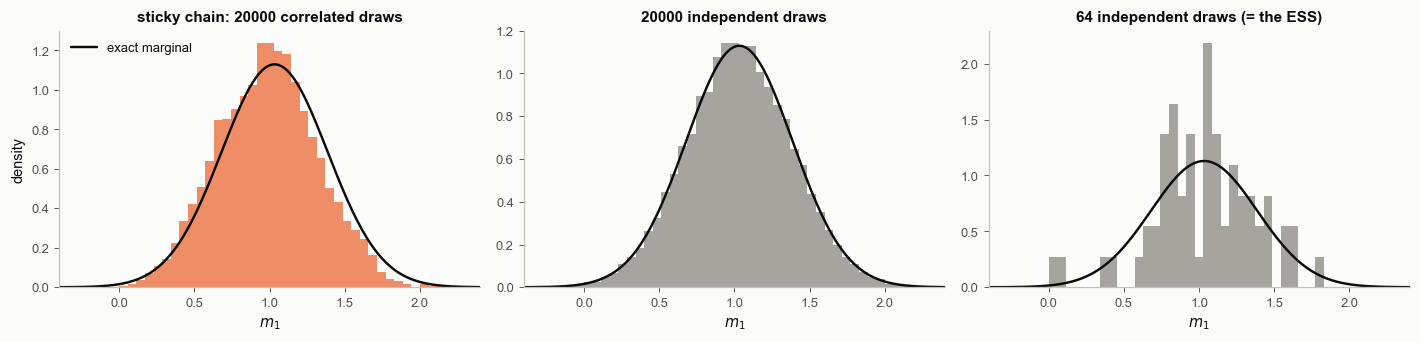

exact posterior mean 1.033, exact posterior sd 0.353
mean of the sticky chain             0.987  (error -0.046; sd/sqrt(ESS) = 0.044)
mean of the 20000 independent draws  1.031  (error -0.002; sd/sqrt(N)   = 0.002)
mean of the ESS independent draws    1.034  (error 0.001)


In [8]:
sticky_run = SM.rwm(gp, m_ex + 0.05 * np.random.default_rng(31).standard_normal((4, 2)), 5000, step=0.05,
                    rng=np.random.default_rng(32))
sticky = sticky_run["samples"][:, :, 0].ravel()
n_eff = max(int(round(D.ess(sticky_run["samples"][:, :, 0]))), 2)
print("sticky chain: acceptance %.2f, ESS %d of %d draws" % (sticky_run["accept_rate"], n_eff, sticky.size))
rng = np.random.default_rng(7)
indep_all = rng.normal(m_ex[0], np.sqrt(C_ex[0, 0]), sticky.size)
indep_eff = rng.normal(m_ex[0], np.sqrt(C_ex[0, 0]), n_eff)
xs, px = gG.marginal(0)
bins = np.linspace(-0.4, 2.4, 50)
fig, axs = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, data, t in zip(axs, [sticky, indep_all, indep_eff],
                       [f"sticky chain: {sticky.size} correlated draws", f"{sticky.size} independent draws",
                        f"{n_eff} independent draws (= the ESS)"]):
    ax.hist(data, bins=bins, density=True, color=ORANGE if data is sticky else S.MUTED, alpha=0.75, lw=0)
    ax.plot(xs, px, color=S.INK, lw=1.6)
    ax.set_title(t, fontsize=10)
    ax.set_xlabel("$m_1$")
    ax.set_xlim(-0.4, 2.4)
axs[0].set_ylabel("density")
axs[0].legend(handles=BP.legend_handles([("exact marginal", S.INK, "line")]), loc="upper left")
fig.tight_layout()
bk.savefig(fig, "2-16_ess_meaning")
plt.show()
sd1 = np.sqrt(C_ex[0, 0])
print("exact posterior mean %.3f, exact posterior sd %.3f" % (m_ex[0], sd1))
print("mean of the sticky chain             %.3f  (error %.3f; sd/sqrt(ESS) = %.3f)" % (sticky.mean(), sticky.mean() - m_ex[0], sd1 / np.sqrt(n_eff)))
print("mean of the 20000 independent draws  %.3f  (error %.3f; sd/sqrt(N)   = %.3f)" % (indep_all.mean(), indep_all.mean() - m_ex[0], sd1 / np.sqrt(sticky.size)))
print("mean of the ESS independent draws    %.3f  (error %.3f)" % (indep_eff.mean(), indep_eff.mean() - m_ex[0]))

The sticky chain's histogram has the same kind of irregularities as the small independent sample (bumps, uneven
tails), not the clean shape of the large one. That is what ESS means: **a chain of N correlated draws carries the
information of ESS independent draws.** The Monte Carlo error of a posterior mean scales like
posterior sd / $\sqrt{\text{ESS}}$, not / $\sqrt{N}$ (compare the errors printed above with the two yardsticks).
Keeping every 10th draw ("thinning") does not raise the ESS; it only saves disk space.

## 5. Why trade-offs hurt, and the fix

An isotropic proposal does not know which way the ridge runs, and every step size is a bad compromise. Small
steps fit the narrow direction and are accepted, but crawl along the long one. Large steps could travel along the
ridge in one jump, but almost all of them land off the ridge and are rejected. Below: a 2-D Gaussian with unit
variances and correlation $\rho$.
For each $\rho$ we scan the step size and keep the best ESS per 1000 evaluations of the log posterior, and compare
with proposals **shaped like the posterior** (proposal covariance = posterior covariance × $2.38^2/d$).

   rho | isotropic: best ESS/1000   step   acc |  shaped: ESS/1000   acc
 0.000 |                    123.3  2.138  0.27 |             121.2  0.35
 0.500 |                     99.1  2.138  0.24 |             133.4  0.35
 0.900 |                     48.0  1.398  0.22 |             117.5  0.36
 0.990 |                     14.8  1.398  0.08 |             129.4  0.35
 0.999 |                      4.5  3.270  0.01 |             141.4  0.36


trade-off posterior: best isotropic step 0.68 (acceptance 0.08 over these 300 steps), shaped acceptance 0.34


saved figures/2-16_correlation.png


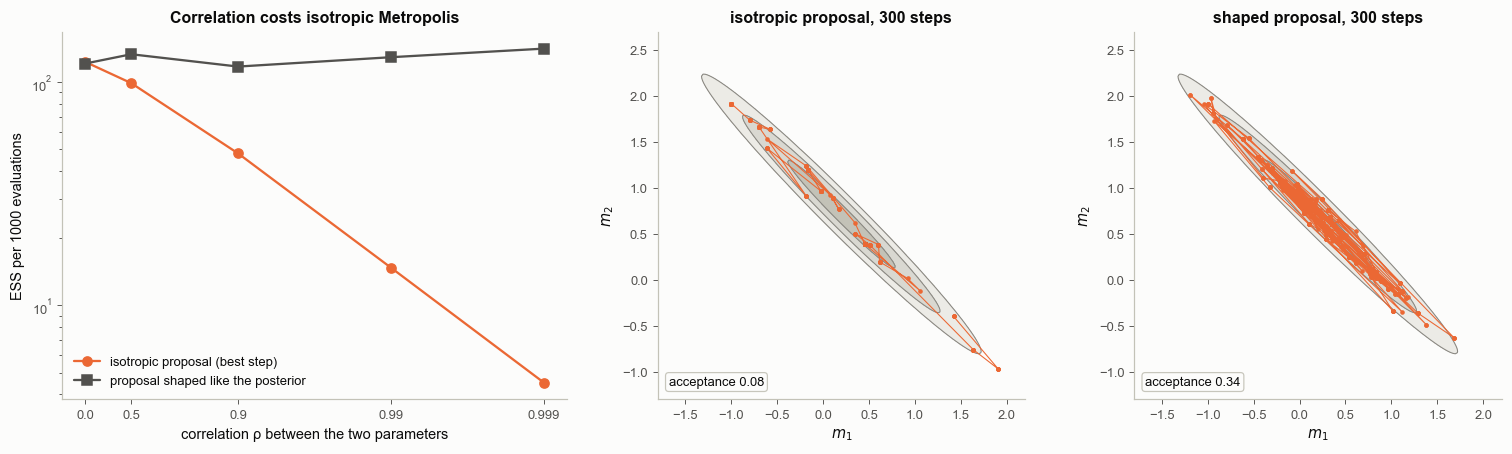

In [9]:
def gauss2(rho):
    Cinv = jnp.asarray(np.linalg.inv(np.array([[1.0, rho], [rho, 1.0]])))
    return P.Target(lambda x: -0.5 * x @ Cinv @ x, 2)


rhos = [0.0, 0.5, 0.9, 0.99, 0.999]
iso_best, shaped = [], []
rng = np.random.default_rng(11)
for rho in rhos:
    t = gauss2(rho)
    best_e, best_s, best_a = 0.0, None, None
    for s in np.geomspace(0.02, 5, 14):
        r = SM.rwm(t, 0.1 * rng.standard_normal((4, 2)), 10000, step=s, rng=rng)
        e = min(D.ess(r["samples"][:, 2000:, 0]), D.ess(r["samples"][:, 2000:, 1])) / (4 * 8000) * 1000
        if e > best_e:
            best_e, best_s, best_a = e, s, r["accept_rate"]
    iso_best.append((best_e, best_s, best_a))
    Csh = np.array([[1.0, rho], [rho, 1.0]]) * 2.38 ** 2 / 2
    r = SM.rwm(t, 0.1 * rng.standard_normal((4, 2)), 10000, step=1.0, cov=Csh, rng=rng)
    shaped.append((min(D.ess(r["samples"][:, 2000:, 0]), D.ess(r["samples"][:, 2000:, 1])) / (4 * 8000) * 1000,
                   r["accept_rate"]))
print(f"{'rho':>6s} | {'isotropic: best ESS/1000':>24s} {'step':>6s} {'acc':>5s} | {'shaped: ESS/1000':>17s} {'acc':>5s}")
for rho, (e, s, a), (es, as_) in zip(rhos, iso_best, shaped):
    print(f"{rho:6.3f} | {e:24.1f} {s:6.3f} {a:5.2f} | {es:17.1f} {as_:5.2f}")

# paths on the trade-off posterior of notebook 2.02, isotropic (best step from a scan) vs shaped
pr = P.correlated()
mC, CC = pr.exact
scanC = []
for s in np.geomspace(0.05, 3, 12):
    r = SM.rwm(pr, np.tile(mC, (4, 1)), 5000, step=s, rng=np.random.default_rng(5))
    scanC.append((D.ess(r["samples"][:, :, 0]), s))
sC = max(scanC)[1]
r_iso = SM.rwm(pr, start, 300, step=sC, rng=np.random.default_rng(8))
r_sh = SM.rwm(pr, start, 300, step=1.0, cov=CC * 2.38 ** 2 / 2, rng=np.random.default_rng(8))
print("trade-off posterior: best isotropic step %.2f (acceptance %.2f over these 300 steps), shaped acceptance %.2f"
      % (sC, r_iso["accept_rate"], r_sh["accept_rate"]))

fig, axs = plt.subplots(1, 3, figsize=(14, 4.2), gridspec_kw=dict(width_ratios=[1.25, 1, 1]))
xpos = [0, 0.301, 1, 2, 3]                                   # -log10(1 - rho)
ax = axs[0]
ax.plot(xpos, [e for e, _, _ in iso_best], "-o", color=ORANGE, label="isotropic proposal (best step)")
ax.plot(xpos, [e for e, _ in shaped], "-s", color=S.INK2, label="proposal shaped like the posterior")
ax.set_yscale("log")
ax.set_xticks(xpos); ax.set_xticklabels([str(r) for r in rhos])
ax.set_xlabel("correlation ρ between the two parameters")
ax.set_ylabel("ESS per 1000 evaluations")
ax.legend(loc="lower left")
ax.set_title("Correlation costs isotropic Metropolis")
for ax, r, t in zip(axs[1:], [r_iso, r_sh], ["isotropic proposal, 300 steps", "shaped proposal, 300 steps"]):
    base_axes(ax)
    c = np.vstack([start, r["chain"]])
    ax.plot(c[:, 0], c[:, 1], "-o", color=ORANGE, lw=0.7, ms=2)
    ax.set_title(t)
    S.badge(ax, f"acceptance {r['accept_rate']:.2f}", loc="lower left")
fig.tight_layout()
bk.savefig(fig, "2-16_correlation")
plt.show()

**The image to keep:** with an isotropic proposal the efficiency falls steadily as the ridge gets thinner (left).
On the trade-off posterior the best isotropic step turns out to be a large one (printed above): the chain rarely
moves (acceptance in the badge), and the few accepted jumps are what carry it along the ridge (middle). Shaping
the proposal like the posterior turns the ellipse back into a circle as far as the sampler is concerned, and the
efficiency stops depending on $\rho$ (right: most proposals are accepted and the whole ridge is covered). In practice the shape is learned from the run itself: adaptive
Metropolis (Haario et al. 2001) estimates the covariance from the chain's own history. CATMIP/AlTar do the same with
the covariance of the weighted particles at each tempering stage (notebook 2.20). A curved ridge (the banana) has no
single shape, so this fix helps only partly there.

## 6. Why dimension hurts

A $d$-dimensional standard Gaussian, step size $2.38/\sqrt d$ (the asymptotically optimal scaling). We count ESS of
one coordinate per 1000 evaluations.

d =   1: acceptance 0.443, ESS per 1000 evaluations  222.30, d x that    222


d =   2: acceptance 0.355, ESS per 1000 evaluations  140.86, d x that    282


d =   5: acceptance 0.287, ESS per 1000 evaluations   60.11, d x that    301


d =  10: acceptance 0.260, ESS per 1000 evaluations   33.78, d x that    338


d =  20: acceptance 0.247, ESS per 1000 evaluations   15.38, d x that    308


d =  50: acceptance 0.238, ESS per 1000 evaluations    6.53, d x that    326


d = 100: acceptance 0.237, ESS per 1000 evaluations    3.05, d x that    305
saved figures/2-16_dimension.png


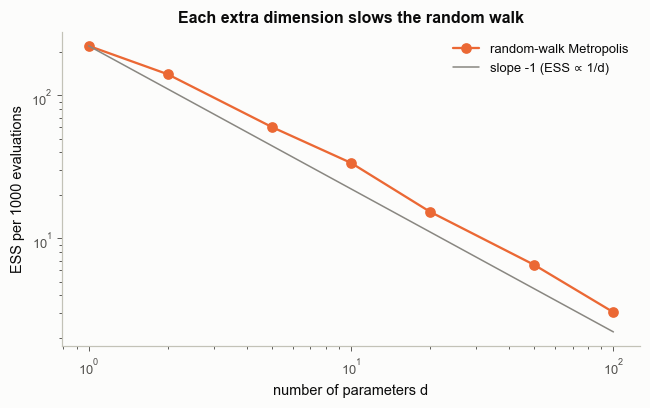

In [10]:
dims = [1, 2, 5, 10, 20, 50, 100]
dim_res = []
rng = np.random.default_rng(12)
for d in dims:
    t = P.Target(lambda x: -0.5 * jnp.sum(x ** 2), d)
    n = 40000
    r = SM.rwm(t, rng.standard_normal((4, d)), n, step=2.38 / np.sqrt(d), rng=rng)
    e = D.ess(r["samples"][:, n // 10:, 0]) / (4 * n * 0.9) * 1000
    dim_res.append((d, r["accept_rate"], e))
    print(f"d = {d:3d}: acceptance {r['accept_rate']:.3f}, ESS per 1000 evaluations {e:7.2f}, d x that {d * e:6.0f}")
dim_res = np.array(dim_res)
fig, ax = plt.subplots(figsize=(6.0, 3.8))
ax.loglog(dim_res[:, 0], dim_res[:, 2], "o-", color=ORANGE, label="random-walk Metropolis")
ref = dim_res[0, 2] * dim_res[0, 0] / dim_res[:, 0]
ax.loglog(dim_res[:, 0], ref, "-", color=S.MUTED, lw=1.0, label="slope -1 (ESS ∝ 1/d)")
ax.set_xlabel("number of parameters d")
ax.set_ylabel("ESS per 1000 evaluations")
ax.set_title("Each extra dimension slows the random walk")
ax.legend()
fig.tight_layout()
bk.savefig(fig, "2-16_dimension")
plt.show()

To keep the acceptance rate reasonable in $d$ dimensions the step must shrink like $1/\sqrt d$, and a random walk
covers a distance that grows only like the square root of the number of steps. The two together make the cost of
one independent draw grow like $d$ evaluations (Roberts, Gelman & Gilks 1997). The printed acceptance rates also
settle towards 0.234 as $d$ grows, which is where that famous number comes from. Hamiltonian methods need of order
$d^{1/4}$ gradient evaluations per independent draw instead (Neal 2011; Beskos et al. 2013): notebook 2.18.

## 7. The banana: short runs miss the tips

Four chains start at the top of the banana from notebook 2.02. Short run vs long run, against the exact posterior (grid).

probability in the tips (|east| > 1.5): exact (grid) 0.122 | short run 0.075 | long run 0.117
acceptance: short 0.37, long 0.36;  ESS of east coordinate: short 12 of 2000 draws, long 754 of 100000 draws
saved figures/2-16_banana_runs.png


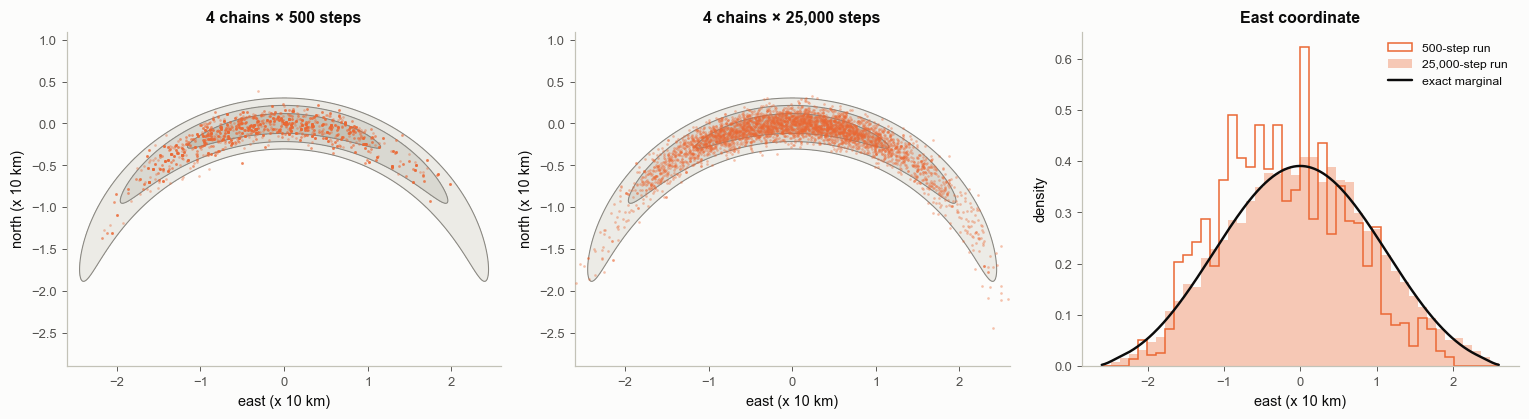

In [11]:
ban = P.location(kind="banana")
gB = P.grid(ban, n=400)
x0s = np.zeros((4, 2))
short = SM.rwm(ban, x0s, 500, step=0.3, rng=np.random.default_rng(21))
long_ = SM.rwm(ban, x0s, 25000, step=0.3, rng=np.random.default_rng(22))
tips_true = gB.mass(lambda X, Y: np.abs(X) > 1.5)
tip_frac = lambda r: np.mean(np.abs(r["samples"][:, :, 0].ravel()) > 1.5)
print("probability in the tips (|east| > 1.5): exact (grid) %.3f | short run %.3f | long run %.3f"
      % (tips_true, tip_frac(short), tip_frac(long_)))
print("acceptance: short %.2f, long %.2f;  ESS of east coordinate: short %.0f of %d draws, long %.0f of %d draws"
      % (short["accept_rate"], long_["accept_rate"], D.ess(short["samples"][:, :, 0]), short["samples"][:, :, 0].size,
         D.ess(long_["samples"][:, :, 0]), long_["samples"][:, :, 0].size))
fig, axs = plt.subplots(1, 3, figsize=(14, 3.9))
for ax, r, t in zip(axs[:2], [short, long_], ["4 chains × 500 steps", "4 chains × 25,000 steps"]):
    BP.density(ax, gB)
    BP.samples(ax, r["samples"].reshape(-1, 2), ORANGE, n_max=4000, s=3, alpha=0.4)
    BP.frame(ax, ban, equal=True)
    ax.set_title(t)
xs, px = gB.marginal(0)
ax = axs[2]
bins = np.linspace(-2.6, 2.6, 45)
ax.hist(short["samples"][:, :, 0].ravel(), bins=bins, density=True, histtype="step", color=ORANGE, lw=1.0, label="500-step run")
ax.hist(long_["samples"][:, :, 0].ravel(), bins=bins, density=True, color=ORANGE, alpha=0.35, lw=0, label="25,000-step run")
ax.plot(xs, px, color=S.INK, lw=1.6, label="exact marginal")
ax.set_xlabel(ban.labels[0]); ax.set_ylabel("density")
ax.set_title("East coordinate")
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
bk.savefig(fig, "2-16_banana_runs")
plt.show()

A random walk explores a curved ridge by diffusion: it has to stumble along the arc, and a short run has not yet
carried enough mass into the tips (compare the printed tip probabilities). Nothing in a short run *looks* wrong:
each chain sits happily in high-probability territory. This is the reason diagnostics exist (notebook 2.19).

## Summary

| knob or property | effect on random-walk Metropolis |
|---|---|
| step too small | almost all accepted, tiny moves, slow drift |
| step too large | almost all rejected, chain stuck in place |
| strong trade-off (correlation) | isotropic steps limited by the narrow direction; fix with a proposal shaped like the posterior |
| more parameters | ESS per evaluation falls like 1/d |
| curved ridge | diffusion along the curve; long runs needed |

**In practice.** For a slip model with hundreds of patches and a linear forward model, automatic differentiation
makes the gradient about as cheap as one forward evaluation, and section 6 shows what hundreds of dimensions do to a
random walk; a gradient-based sampler (2.18) is then the usual choice. Metropolis is still everywhere: it is the move
step inside CATMIP-style SMC (with proposals shaped by the particle covariance, 2.20), and it is the fallback
whenever the forward model is a black box without gradients.

Next: [**2.17 · JAX, differentiability, CPU and GPU**](2-17_jax_differentiable.ipynb).